# AP 155 Lab Exercise
---
## Exercise 12: More Integration

_Instructions_: 
- **Problem 1**: Figure: Diffraction Pattern, discussion: Explain the figure
- **Problem 2**: Figure: Gamma Function, discussion: *What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?*
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Buhangin, Ahrystan Deniz
- _Student No._: 2024-07766
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="Figures/bessel.png" alt="bessel" width=45%>

<img src="Figures/gamma.png" alt="gamma" width=45%>

### Report discussion

#### Problem 1
The first figure above shows the diffraction pattern produced by a star, treated as a point light source, as its light passes through the circular aperture of a telescope. We can observe a very bright central spot along with concentric rings around it. The intensity of these rings are proportional to the square of the first order Bessel function. 

#### Problem 2
The difference between the Monte Carlo used here and last time is the sampling through the function $p(t)$ instead, allowing us to easily integrate over the bounds of the gamma function. There are some important considerations when applying MC with importance sampling. These cases include when $p(t)$ decays faster than $g(t)$, at which case the variance becomes infinite close to $t=0$., or when $p(t)$ is not strictly positive everywhere, at which point the integration may miss certain regions and sampling becomes biased.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy as sc

### Problem 1: Diffraction limit of a telescope

![Screenshot 2026-11-09 at 5.08.50 PM.png](DiffLimitTelescopeNeumann5-4.png)

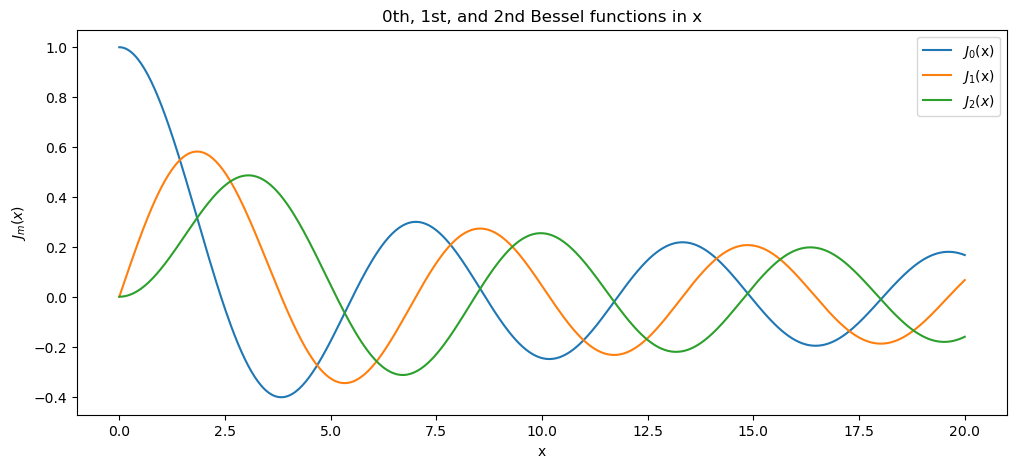

In [2]:
a, b, N = 0, np.pi, 1000
X = np.linspace(0, 20, 500)

def J(m, x):
    theta = np.linspace(a, b, N+1)
    h = (b - a) / N
    cs = 2*np.ones(N + 1)
    cs[1::2] = 4; cs[0] = 1; cs[-1] = 1
    y = np.cos(m*theta - x*np.sin(theta))
    contribs = cs*y
    estimate = (h / 3) * np.sum(contribs)
    return (1/np.pi) * estimate

J_vec = np.vectorize(J, excluded=['m']) #Required to avoid unwanted vector operations

plt.figure(figsize=(12, 5))
plt.title("0th, 1st, and 2nd Bessel functions in x")
plt.xlabel("x")
plt.ylabel("$J_m(x)$")
plt.plot(X, J_vec(0, X), label="$J_0$(x)"),
plt.plot(X, J_vec(1, X), label="$J_1$(x)")
plt.plot(X, J_vec(2, X), label="$J_2(x)$")
plt.legend()

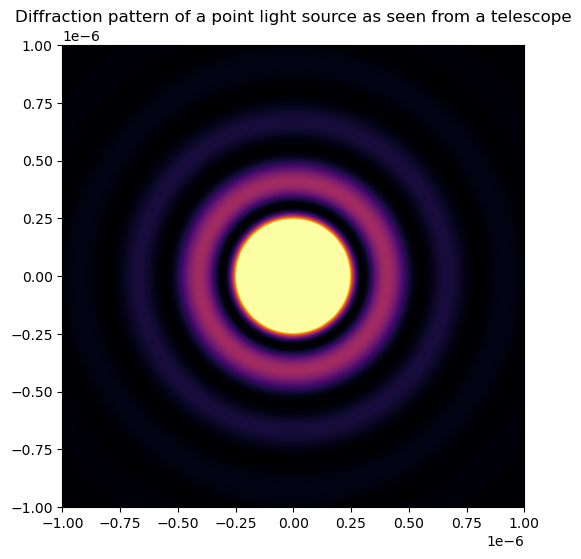

In [3]:
lambd = 500e-9
k = 2*np.pi/lambd
x = np.linspace(-1e-6, 1e-6, 500)
y = np.linspace(-1e-6, 1e-6, 500)
X, Y = np.meshgrid(x, y)
R = np.sqrt(X**2 + Y**2)

def getIntensity(r):
    num = J_vec(1, k*r)
    den = k*r
    return((num/den)**2)

I = []
for r in R:
  I.append(getIntensity(r))
I = np.array(I)

plt.figure(figsize=(6,6))
plt.imshow(I, extent = [-1e-6, 1e-6,-1e-6, 1e-6], cmap='inferno', vmax=0.01)
plt.title("Diffraction pattern of a point light source as seen from a telescope")
plt.savefig('/home/jovyan/Buhangin_AP155/AP155_TX1_1sAY2627/ahrystanB/Figures/bessel.png')


Hint 1: You may find it useful to know that $\lim_{x→0} J_1(x)/x = 1/2$ 

Hint 2: The central
spot in the diffraction pattern is so bright that it may be difficult to see the rings around
it on the computer screen. If you run into this problem a simple way to deal with it is to
use one of the other color schemes for density plots described in Section 3.3. The “hot”
scheme works well. For a more sophisticated solution to the problem, the imshow function has an additional argument vmax that allows you to set the value that corresponds
to the brightest point in the plot. For instance, if you say `imshow(x,vmax=0.1)`, then elements in x with value 0.1, or any greater value, will produce the brightest (most positive) color on the screen. By lowering the `vmax` value, you can reduce the total range of
values between the minimum and maximum brightness, and hence increase the sensitivity of the plot, making subtle details visible. (There is also a `vmin` argument that can
be used to set the value that corresponds to the dimmest (most negative) color.) For this
exercise a value of `vmax=0.01` appears to work well.

Report discussion: Explain the figure

### Summary of Problem 1 code

the function $J(m, x)$ is defined such that it inputs what order of the Bessel function is needed, along with any value of x to which it should be evaluated at. The getIntensity function, on the otherhand, simply implements the equation for the diffraction of a point light source. The two plots showcase the first 3 orders of the Bessel function, and the diffraction pattern produced by a point light source as viewed through a telescope aperture.

### Problem 2: Integration via Monte Carlo with Importance sampling

Evaluate the gamma function for $z\in [0,5]$ $$ \Gamma(z) = \int_{0}^{\infty} t^{z-1} e^{-t} \, dt $$. Plot the function using your integration method vs `scipy.special.gamma` (two curves)

Use monte carlo method with importance sampling, by recasting the integral into the form 

$$ \int f(x)dx = \int g(x)p(x)dx, \ \  g(x) = \frac{f(x)}{p(x)}$$



Report discussion: What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?

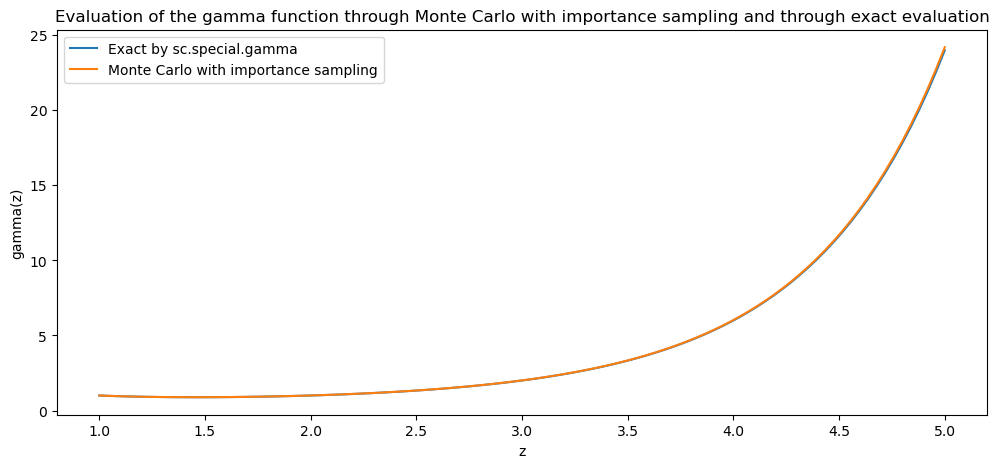

In [4]:
N=200000
Z = np.linspace(1, 5, 100)
T = np.random.exponential(scale=1.0, size=N)

def gamma_mc(z, t):
    g_t = t ** (z-1)
    return np.mean(g_t)

mc_estimates = np.array([gamma_mc(z, T) for z in Z])

plt.figure(figsize=(12, 5))
plt.plot(Z, sc.special.gamma(Z), label='Exact by sc.special.gamma')
plt.plot(Z, mc_estimates, label='Monte Carlo with importance sampling')
plt.title("Evaluation of the gamma function through Monte Carlo with importance sampling and through exact evaluation")
plt.xlabel("z")
plt.ylabel("gamma(z)")
plt.legend()
plt.savefig('/home/jovyan/Buhangin_AP155/AP155_TX1_1sAY2627/ahrystanB/Figures/gamma.png')

### Summary of Problem 2 code

Since the gamma function already contains the standard $e^{-t}$ distribution which is normalized for the domain $(0, +inf)$, we can immediately already choose it as our $p(t)$ with a corresponding $g(t)=t^{z-1}$. T can then be sampled using random.exponential and used in the above implementation of the Monte Carlo. The results using our MC estimate and the exact sciPy evalu